In [1]:
# SETUP
# `src` is the local package of this repository (run the notebook from the repository root).
# It is imported as `mk`. `data` will hold one NASA POWER time series per location of the
# district.
import src as mk

data = mk.MultiDataFrame()

In [2]:
# Study-area label used in the figure titles below.
district = "Gawadar"

In [3]:
# STEP 1 - DOWNLOAD DAILY TEMPERATURE (NASA POWER)
# Variables: T2M, T2M_MAX, T2M_MIN (2 m air temperature: mean, maximum, minimum, deg C).
# Defaults: daily data, 1981-01-01 to 2025-12-31, community 'AG'. One fetch_and_add call per
# location (tehsil / sub-tehsil) given by decimal-degree coordinates. Requires internet
# access.
# Variables requested for every location below.
data.set_default_parameters("T2M,T2M_MAX,T2M_MIN")



# name = label used in plots; lat/lon = decimal degrees (WGS84). Same pattern for each
# location.
data.fetch_and_add(name="Gwadar",lat=25.12648,lon=62.3225)


data.fetch_and_add(name="Jiwani",lat=25.0504,lon=61.7420)


data.fetch_and_add(name="Pasni",lat=25.2624,lon=63.4713)


data.fetch_and_add(name="Ormara",lat=25.2144, lon=64.6333)


data.fetch_and_add(name="Suntar",lat=25.5022, lon=61.9817)

INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.126480 | Lon: 62.322500 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.050400 | Lon: 61.742000 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.262400 | Lon: 63.471300 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.214400 | Lon: 64.633300 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.502200 | Lon: 61.981700 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.


In [4]:
# Work on a deep copy so the raw daily download in `data` is preserved (it is reused for the
# heatwave analysis below).
data1 = data.copy()

In [5]:
# STEP 2 - ANNUAL MEAN TEMPERATURE
# Replace each daily series by its annual mean of T2M (one value per year, 1981-2025).
# Loop over the locations (integer keys 0, 1, 2, ...).
for i in data1.keys():
    data1[i] = data1[i].transform(["T2M"]).to_annual(method="mean")

In [6]:
# Plotting setup.
# seaborn: line plot of all locations on one axis.
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
# Apply the project's Matplotlib style sheet (relative path, so run the notebook from the
# repository root).
plt.style.use("./deeplearning.mplstyle")

<>:18: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:18: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/tmp/ipykernel_38216/582566016.py:18: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax.set_title(f"District {district} Avg. Temperature ($^\circ$C)", loc="left",


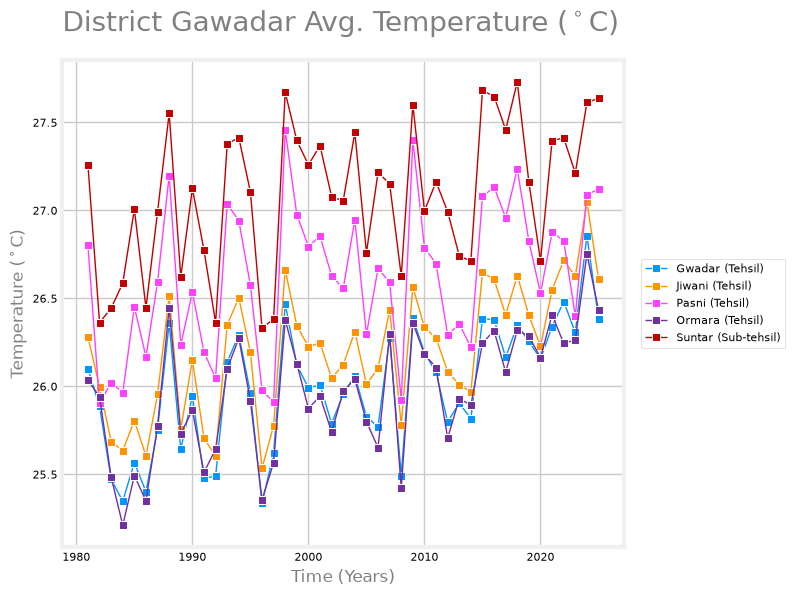

In [7]:
# FIGURE 1 - Annual mean temperature of all locations of the district on one axis.
# Single axis shared by all locations.
fig, ax = plt.subplots(figsize=(8, 6))

# One line per location.
for i in data1.keys():
    # The legend label records the administrative level (tehsil or sub-tehsil) of each
    # location; line style / marker may differ per location.
    if (data1.meta_data[i]["name"] in ["Suntar"]):
        sns.lineplot(data=data1[i], x="Date", y="T2M", marker="s",lw = 1,label=f"{data1.meta_data[i]["name"]} (Sub-tehsil)")
    else:
        sns.lineplot(data=data1[i], x="Date", y="T2M", marker="s",lw = 1,label=f"{data1.meta_data[i]["name"]} (Tehsil)")



# Axis labels, grid and title (final versions are set further below).
plt.xlabel("Date")
plt.ylabel("T2M")

# Legend outside the plot
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.grid()

# Figure title, left-aligned in grey.
ax.set_title(f"District {district} Avg. Temperature ($^\circ$C)", loc="left",
             fontsize=20, color="gray", pad=20)

plt.xlabel(r"Time (Years)",fontsize=12,color = "gray")
plt.ylabel(r"Temperature ($^\circ$C)",fontsize=12,color = "gray")

plt.tight_layout()
plt.show()

In [8]:
# Fresh copy of the raw daily data for the trend analysis.
data2 = data.copy()

In [9]:
# Annual mean T2M again (same aggregation as above), this time as input for the trend test.
# Loop over the locations.
for i in data2.keys():
    data2[i] = data2[i].transform(["T2M"]).to_annual(method="mean")

Gwadar  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(11.64885635072976), Tau=np.float64(0.43232323232323233), s=np.float64(428.0), var_s=np.float64(1343.6593252426114), slope=np.float64(0.016821448587245862), intercept=np.float64(25.638859637929905))
Jiwani  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(11.32522391428384), Tau=np.float64(0.4202020202020202), s=np.float64(416.0), var_s=np.float64(1342.7729960893216), slope=np.float64(0.017642867026428737), intercept=np.float64(25.83912468498141))
Pasni  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(9.257787653525307), Tau=np.float64(0.26666666666666666), s=np.float64(264.0), var_s=np.float64(807.0437280526056), slope=np.float64(0.01223063103525724), intercept=np.float64(26.359419267909274))
Ormara  =  Modified_Mann_Kendall_Test_Yue_Wang_Appr

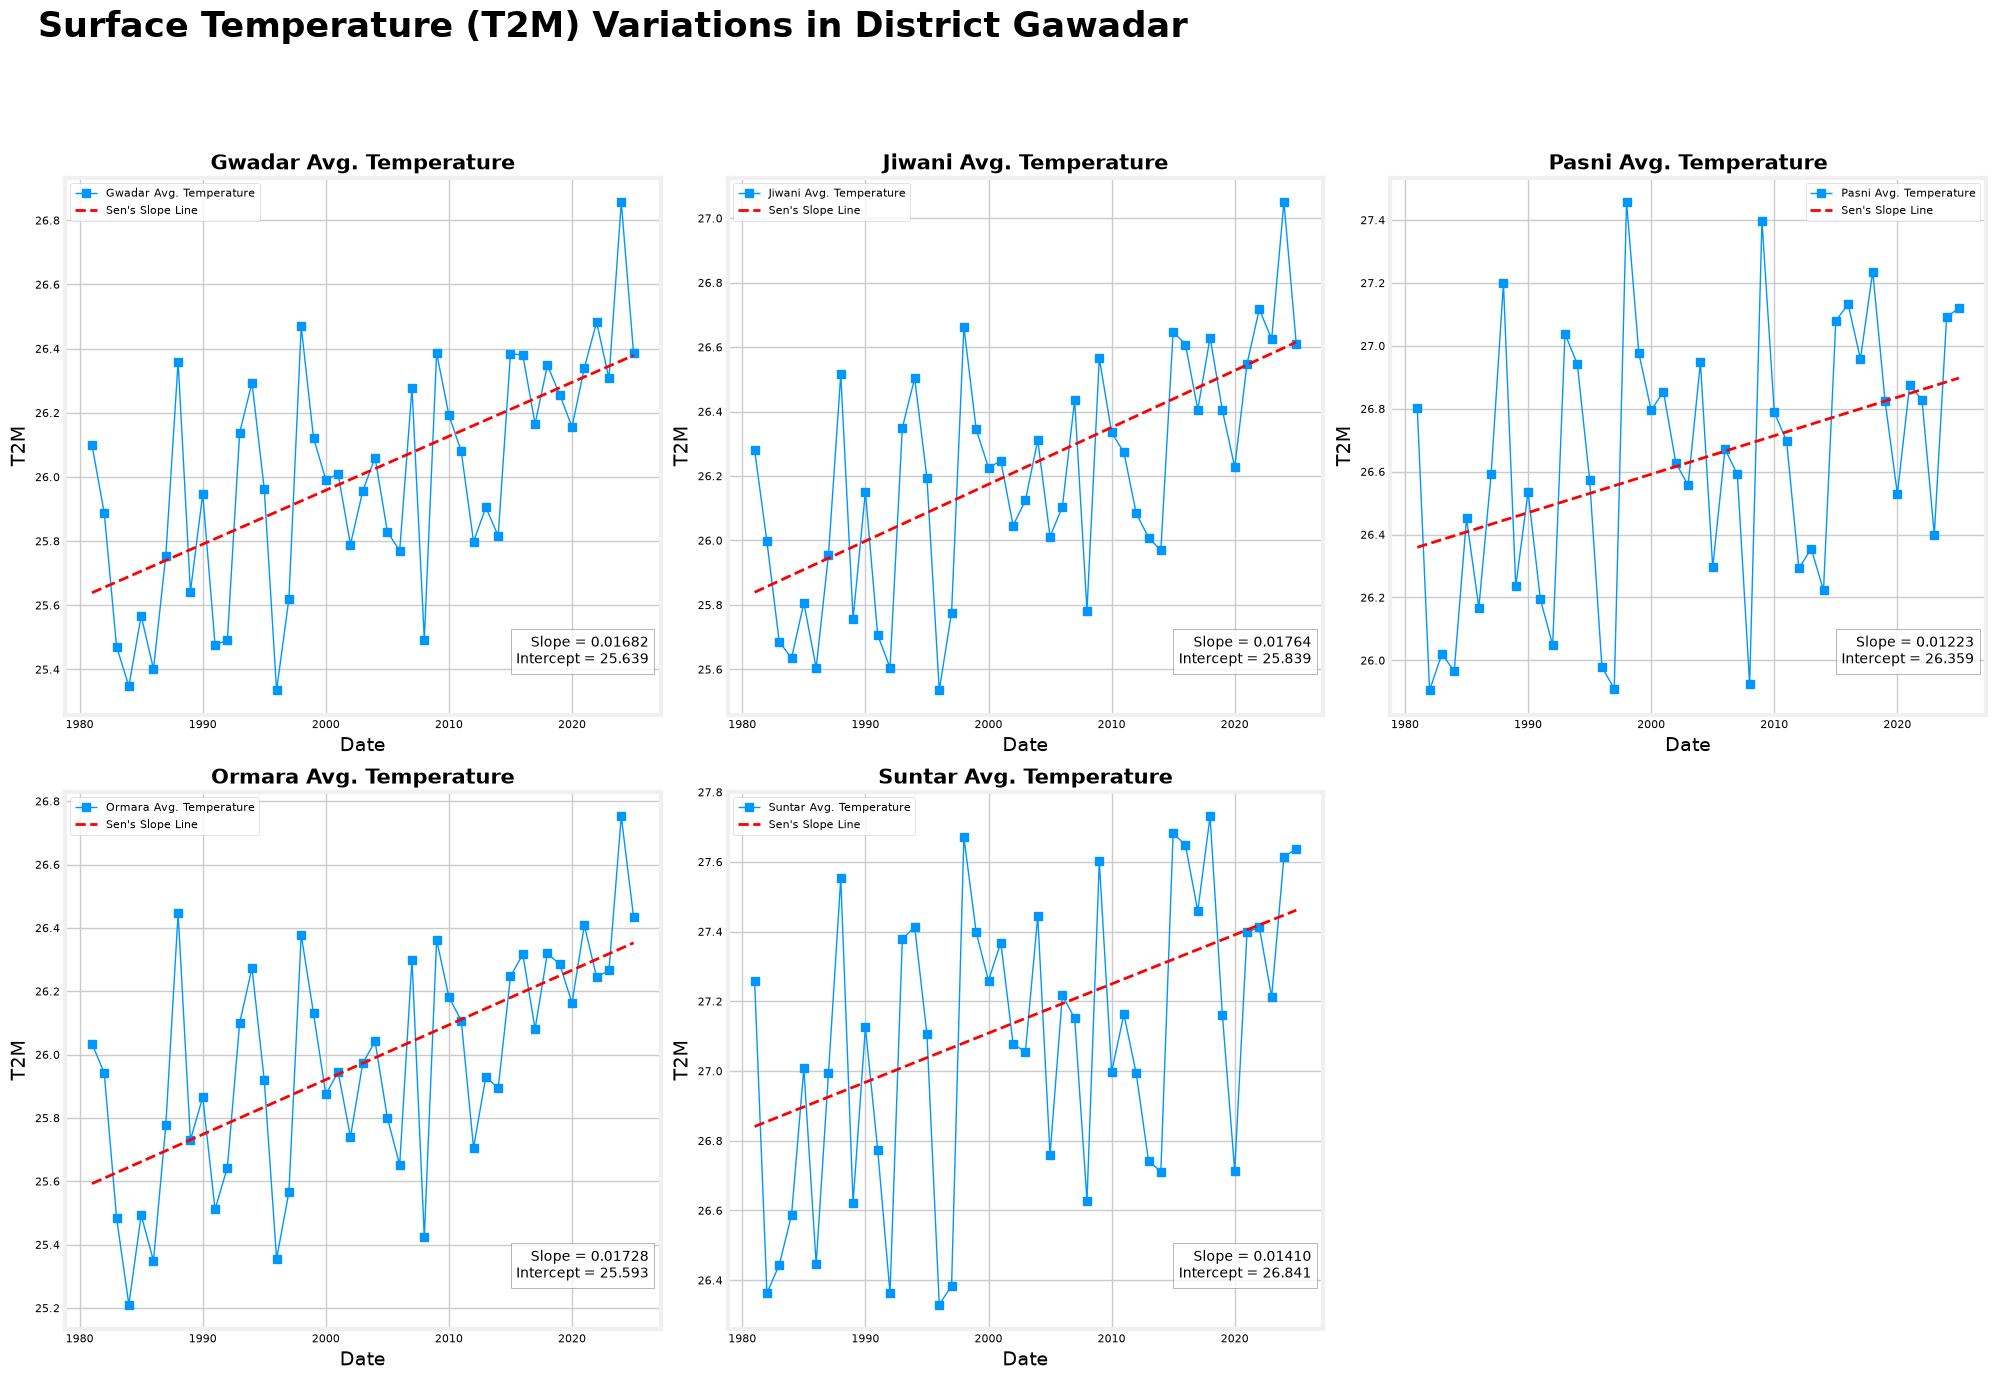

In [10]:
# FIGURE 2 - ANNUAL MEAN TEMPERATURE TREND PER LOCATION
# One panel per location with its Modified Mann-Kendall / Sen's slope trend line.
# Grid of panels, one per location (unused panels are removed below).
fig, ax = plt.subplots(2, 3, figsize=(20, 14))
# Flat list of Axes: panel i belongs to location key i.
ax_plots = [
    ax[0,0],ax[0,1],ax[0,2],
    ax[1,0],ax[1,1],ax[1,2]
]

# Loop over the locations.
for i in data2.keys():
    # Plot the annual mean T2M of location i, then overlay the trend line.
    # Fit and draw the trend line with the Modified Mann-Kendall test (Yue-Wang variance
    # correction for autocorrelation, via pymannkendall); the line is Sen's slope. The
    # returned object holds trend, h, p, z, Tau, s, var_s, slope and intercept.
    trend = data2[i].chart("T2M",ax = ax_plots[i],lw=1,marker = "s",label = f"{data2.meta_data[i]["name"]} Avg. Temperature").mann_kendall("yue_wang_modification_test",color="red",linestyle="--",linewidth=2,label="Sen's Slope Line")
    ax_plots[i].set_title(f"{data2.meta_data[i]["name"]} Avg. Temperature", fontsize=15, fontweight="bold")
    ax_plots[i].grid()
    ax_plots[i].set_xlabel("Date", fontsize=14)
    ax_plots[i].set_ylabel("T2M", fontsize=14)
    ax_plots[i].legend()

    # Print the full test result for this location (trend, h, p, z, Tau, s, var_s, slope,
    # intercept).
    print(data2.meta_data[i]["name"]," = ",trend)
    # Visual separator between locations in the printed output.
    print(200*"==")

    # Annotate the panel with the fitted slope and intercept.
    ax_plots[i].text(
            0.98, 0.15,
            f"Slope = {trend.slope:.5f}\nIntercept = {trend.intercept:.3f}",
            transform=ax_plots[i].transAxes,
            fontsize=10,
            va="top",
            ha="right",
            bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
        )


# Overall figure title.
fig.suptitle(
    f"Surface Temperature (T2M) Variations in District {district}",
    x=0.02,          # left aligned
    ha="left",
    fontsize=25,
    fontweight="bold"
)

# Delete the unused panel(s) of the grid.
ax_plots[5].remove()
# Leave room at the top for the overall title.
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


In [11]:
# STEP 3 - RAINFALL
# New container for precipitation, so the temperature data above are not mixed with it.
data3 = mk.MultiDataFrame()

In [12]:
# Download daily bias-corrected precipitation (PRECTOTCORR, mm/day) for the same locations
# and period.
# Precipitation variable only.
data3.set_default_parameters("PRECTOTCORR")



# Same locations as in the temperature download above.
data3.fetch_and_add(name="Gwadar",lat=25.12648,lon=62.3225)


data3.fetch_and_add(name="Jiwani",lat=25.0504,lon=61.7420)


data3.fetch_and_add(name="Pasni",lat=25.2624,lon=63.4713)


data3.fetch_and_add(name="Ormara",lat=25.2144, lon=64.6333)


data3.fetch_and_add(name="Suntar",lat=25.5022, lon=61.9817)

INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.126480 | Lon: 62.322500 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.050400 | Lon: 61.742000 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.262400 | Lon: 63.471300 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.214400 | Lon: 64.633300 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.
INFO:src.weather_api.nasa_power:Fetching data | Lat: 25.502200 | Lon: 61.981700 | Period: 1981-01-01 → 2025-12-31
INFO:src.weather_api.nasa_power:Data fetched successfully.


In [15]:
# Copy of the raw precipitation data.
data4 = data3.copy()

In [16]:
# Annual precipitation totals: sum of the daily values (mm/year).
# Loop over the locations.
for i in data4.keys():
    data4[i] = data4[i].transform(["PRECTOTCORR"]).to_annual(method="sum")

Gwadar  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='no trend', h=np.False_, p=np.float64(0.06344366306197924), z=np.float64(1.8560694254000374), Tau=np.float64(0.1292929292929293), s=np.float64(128.0), var_s=np.float64(4681.866310601149), slope=np.float64(0.8104135338345864), intercept=np.float64(53.220902255639096))
Jiwani  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.014428586554589229), z=np.float64(2.4464123743817745), Tau=np.float64(0.12525252525252525), s=np.float64(124.0), var_s=np.float64(2527.847633733169), slope=np.float64(0.6890416666666664), intercept=np.float64(68.13108333333335))
Pasni  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='no trend', h=np.False_, p=np.float64(0.9727359496891423), z=np.float64(0.03417707207774696), Tau=np.float64(0.00404040404040404), s=np.float64(4.0), var_s=np.float64(7705.002798630918), slope=np.float64(0.016428571428571362), intercept=np.float64(52.66857142857143))
Ormara  =

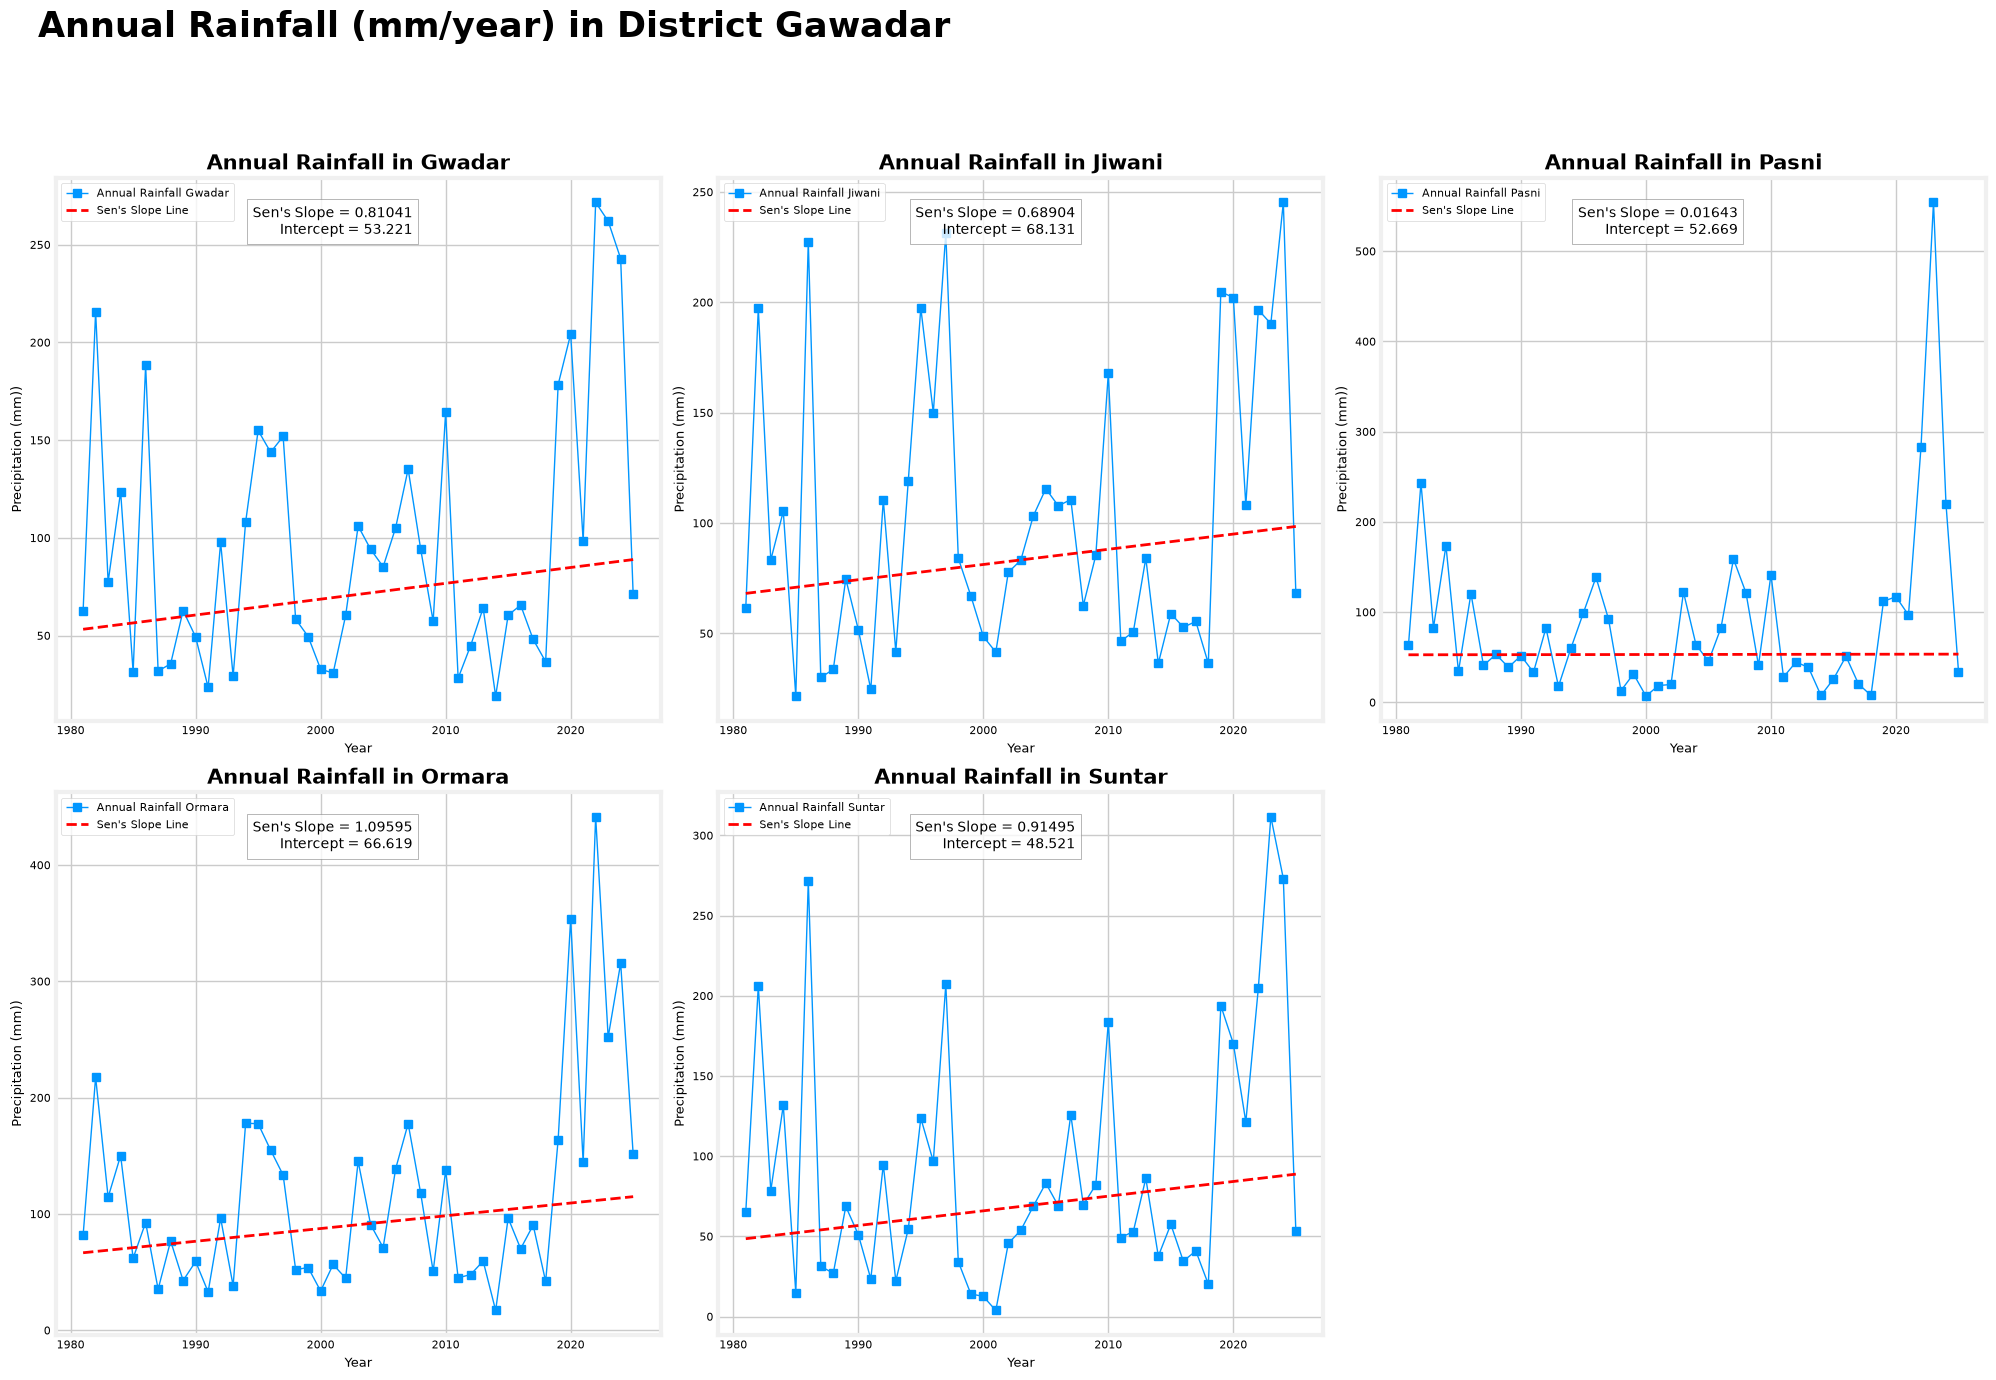

In [17]:
# FIGURE 3 - ANNUAL RAINFALL TREND PER LOCATION
# Annual totals with Modified Mann-Kendall / Sen's slope trend line.
import matplotlib.pyplot as plt

# Grid of panels, one per location.
fig, ax = plt.subplots(2, 3, figsize=(20, 14))
# Flat list of Axes: panel i belongs to location key i.
ax_plots = [
    ax[0,0],ax[0,1],ax[0,2],
    ax[1,0],ax[1,1],ax[1,2]
]

# Loop over the locations (`data` and `data4` have the same keys, so `data` supplies the
# location names).
for i in range(len(data.keys())):
    # Plot the annual rainfall total of location i, then overlay the trend line.
    # Fit and draw the trend line with the Modified Mann-Kendall test (Yue-Wang variance
    # correction for autocorrelation, via pymannkendall); the line is Sen's slope. The
    # returned object holds trend, h, p, z, Tau, s, var_s, slope and intercept.
    trend = data4[i].chart("PRECTOTCORR",ax = ax_plots[i], marker="s", label=f"Annual Rainfall {data.meta_data[i]["name"]}", lw=1).mann_kendall("yue_wang_modification_test",color="red",linestyle="--",linewidth=2,label="Sen's Slope Line")
    
    # Print the full test result for this location.
    print(data4.meta_data[i]["name"]," = ",trend)
    # Visual separator between locations in the printed output.
    print(200*"==")
    
    ax_plots[i].set_title(f"Annual Rainfall in {data.meta_data[i]["name"]}", fontsize=15, fontweight="bold")
    ax_plots[i].grid()
    ax_plots[i].set_xlabel("Year")
    ax_plots[i].set_ylabel("Precipitation (mm))")
    # Annotate the panel with Sen's slope and intercept.
    ax_plots[i].text(
        0.59, 0.95,
        f"Sen's Slope = {trend.slope:.5f}\nIntercept = {trend.intercept:.3f}",
        transform=ax_plots[i].transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
    )
    ax_plots[i].legend(loc="upper left")

# Overall figure title.
fig.suptitle(
    f"Annual Rainfall (mm/year) in District {district}",
    x=0.02,          # left aligned
    ha="left",
    fontsize=25,
    fontweight="bold"
)
# Delete the unused panel(s) of the grid.
ax[1,2].remove()
# Leave room at the top for the overall title.
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [18]:
# STEP 4 - HEATWAVE DAYS
# Start again from the raw daily temperature download (`data`); the heatwave index uses
# T2M_MAX.
data5 = data.copy()

In [19]:
# Remove 29 February so that every year has 365 days (required by the heatwave function).
for i in data5.keys():
    # In-place removal of 29 February for each location.
    data5[i].drop_leap_days(inplace = True)

In [20]:
# Replace each daily series by the annual number of heatwave days (column
# Total_Heatwave_Days). A heatwave day belongs to a run of at least 3 consecutive days whose
# T2M_MAX anomaly exceeds the day-of-year 90th percentile of the 1981-2010 baseline. Wrapped
# in mk.DataFrame so .chart() is available.
for i in data5.keys():
    # Output: DataFrame indexed by year (1981-2025) with the single column
    # Total_Heatwave_Days.
    data5[i] = mk.DataFrame(mk.heatwave(data5[i]))

In [21]:
# Copy of the heatwave-day counts for plotting.
data6 = data5.copy()

Gwadar  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(0.0006873249009007321), z=np.float64(3.394585837427602), Tau=np.float64(0.27474747474747474), s=np.float64(272.0), var_s=np.float64(6373.309245533743), slope=np.float64(0.4166666666666667), intercept=np.float64(7.833333333333332))
Jiwani  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(5.4049636619035724e-05), z=np.float64(4.037387992052788), Tau=np.float64(0.36464646464646466), s=np.float64(361.0), var_s=np.float64(7950.6754824531445), slope=np.float64(0.5), intercept=np.float64(8.0))
Pasni  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(trend='increasing', h=np.True_, p=np.float64(8.001599383078428e-12), z=np.float64(6.8385187066648285), Tau=np.float64(0.21313131313131314), s=np.float64(211.0), var_s=np.float64(943.0061192837879), slope=np.float64(0.25), intercept=np.float64(10.5))
Ormara  =  Modified_Mann_Kendall_Test_Yue_Wang_Approach(tr

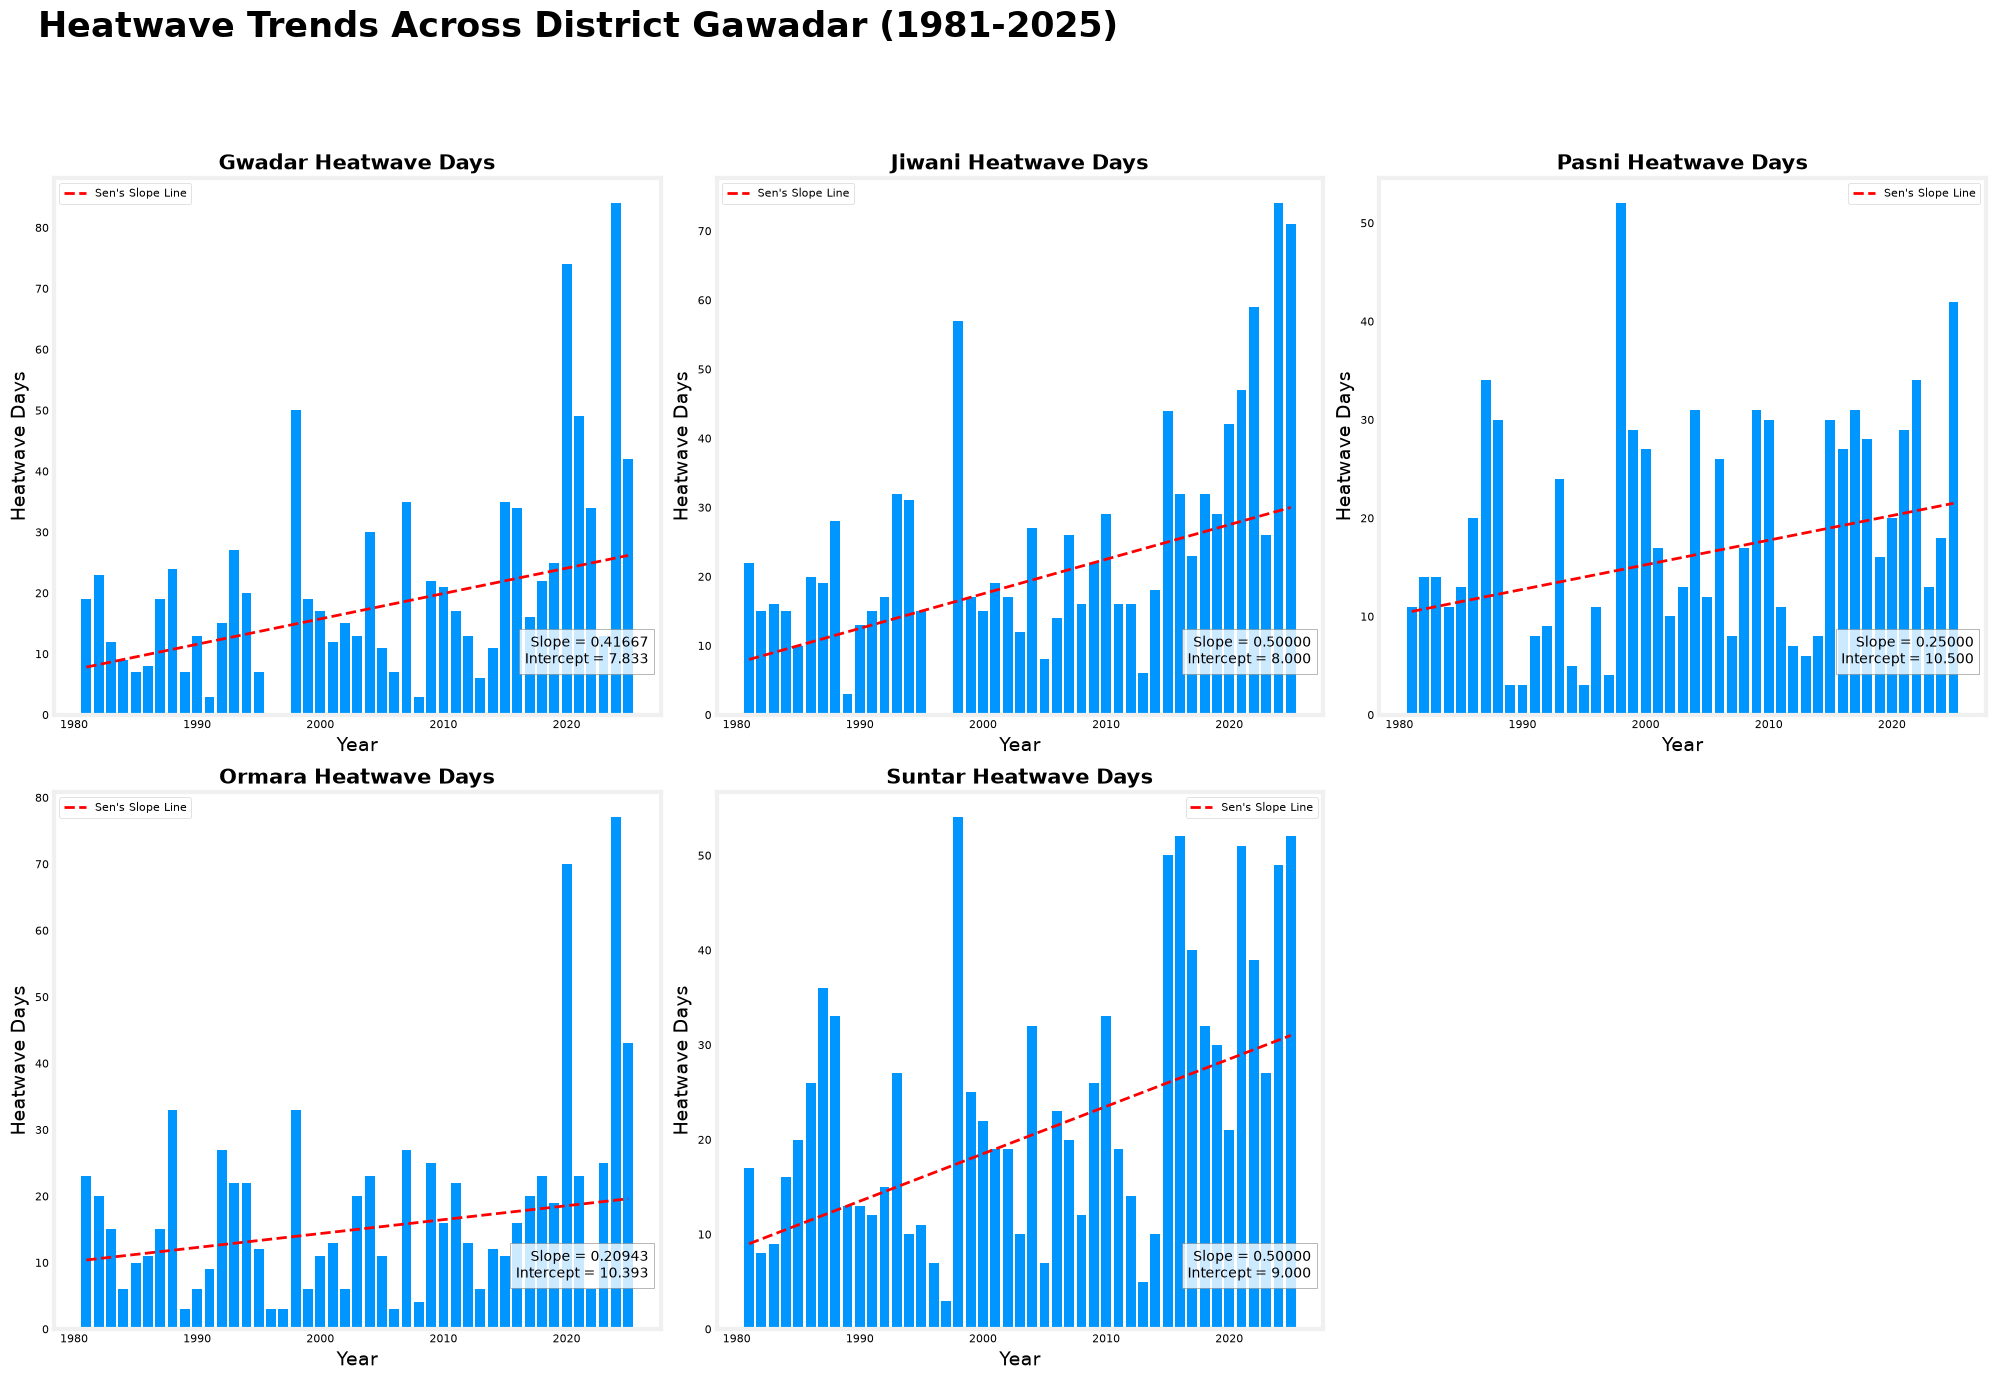

In [22]:
# FIGURE 4 - ANNUAL HEATWAVE-DAY TREND PER LOCATION
# Bar chart of heatwave days per year with Modified Mann-Kendall / Sen's slope trend line.
import matplotlib.pyplot as plt

# Grid of panels, one per location.
fig, ax = plt.subplots(2, 3, figsize=(20, 14))
# Flat list of Axes: panel i belongs to location key i.
ax_plots = [
    ax[0,0],ax[0,1],ax[0,2],
    ax[1,0],ax[1,1],ax[1,2]
]


# Loop over the locations.
for i in data6.keys():
    # Bar chart of annual heatwave days for location i, then the trend line.
    # Fit and draw the trend line with the Modified Mann-Kendall test (Yue-Wang variance
    # correction for autocorrelation, via pymannkendall); the line is Sen's slope. The
    # returned object holds trend, h, p, z, Tau, s, var_s, slope and intercept.
    trend = data6[i].chart("Total_Heatwave_Days",ct="bar",ax = ax_plots[i]).mann_kendall("yue_wang_modification_test",color="red",linestyle="--",linewidth=2,label="Sen's Slope Line")
    
    # Print the full test result for this location.
    print(data6.meta_data[i]["name"]," = ",trend)
    # Visual separator between locations in the printed output.
    print(200*"==")
    
    ax_plots[i].set_title(f"{data.meta_data[i]["name"]} Heatwave Days", fontsize=15, fontweight="bold")
    ax_plots[i].legend()
    ax_plots[i].set_xlabel("Year", fontsize=14)
    ax_plots[i].set_ylabel("Heatwave Days", fontsize=14)


    # Annotate the panel with the fitted slope and intercept.
    ax_plots[i].text(
        0.98, 0.15,
        f"Slope = {trend.slope:.5f}\nIntercept = {trend.intercept:.3f}",
        transform=ax_plots[i].transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
    )

# Overall figure title.
fig.suptitle(
    f"Heatwave Trends Across District {district} (1981-2025)",
    x=0.02,          # left aligned
    ha="left",
    fontsize=25,
    fontweight="bold"
)

# Delete the unused panel(s) of the grid.
ax_plots[5].remove()
# Leave room at the top for the overall title.
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()